K-means clustering an unsupervised machine learning model to identify patterns between data or clusters in this case. The model first assings a random data point/ cluster for the number of clusters mentioned and then measures the euclidean distance of every data point from every cluster, then for every data point, based on its distance from the centre of each cluster we can assign it to that particular cluster, then we take the mean/centroid of all the data points in this initial cluster and then run the clustering algorithm again using these new centroids, when the centroids dont change anymore after multiple iterations, that is when we are finished with the algorithm. But we also need to find the number of clusters, to find this we can run K-Means on multiple different values of K, and find the sum of squared error  and plot a graph between the two, and the elbow point is the ideal K value. 


Step 1 is loading the dataset and cleaning it

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [2]:
data = pd.read_csv("seeds_data.csv")
data


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


In [3]:
data.describe()
data.isnull().sum()
#no null values, lets go!

Feature_1    0
Feature_2    0
Feature_3    0
Feature_4    0
Feature_5    0
Feature_6    0
Feature_7    0
Class        0
dtype: int64

In [4]:
#we cant use the last column for training as each class represents a cluster
y_test = data['Class'].to_numpy().astype('float')
y_test

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
       3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
       3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
       3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
       3., 3., 3., 3., 3., 3.])

In [5]:
train_data = data.drop('Class',axis = 1)
train_data

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175
...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044


In [6]:
#lets scale the data using min max scaling
train_data = (train_data - train_data.min())/(train_data.max()-train_data.min())*9 + 1
train_data

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
0,4.968839,5.518595,6.137024,5.378378,5.374911,2.703715,4.106352
1,4.645892,5.016529,6.961887,4.319257,5.509622,1.295947,2.936484
2,4.144476,4.123967,8.913793,2.986486,5.535282,3.263077,2.355982
3,3.762040,3.845041,8.137931,3.153716,5.804704,2.748183,2.267356
4,5.716714,5.797521,8.783122,4.846284,6.978617,1.690309,3.906942
...,...,...,...,...,...,...,...
205,2.359773,2.469008,6.733212,2.206081,3.251604,4.353717,2.555391
206,1.543909,1.873967,4.511797,2.221284,2.058446,5.165845,3.144756
207,3.218130,3.324380,7.549909,2.707770,4.861725,9.835000,3.379616
208,2.062323,2.487603,4.593466,2.398649,2.321454,4.315100,3.326440


In [7]:
train_data.describe()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,4.618292,4.996606,6.136907,4.696959,5.032390,4.434697,4.939755
std,2.472832,2.428436,1.929807,2.245254,2.422972,1.759484,2.177905
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.427762,2.933884,4.985481,2.840794,3.014255,3.102173,3.330871
50%,4.199717,4.551653,6.337114,4.164696,4.893799,4.316270,4.119645
75%,6.706799,7.145661,7.507033,6.476774,6.977014,5.685128,7.017725
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


step 2 - get random centroids


In [8]:
def get_centroids(train_data,k):
    centroids = []
    for i in range(k):
        centroid = train_data.apply(lambda x: float(x.sample().iloc[0]))
        centroids.append(centroid)

    return pd.concat(centroids,axis = 1)

centroid = train_data.sample().iloc[0].astype('float')

centroid

In [9]:
centroids = get_centroids(train_data,7)
centroids

,0,1,2,3,4,5,6
Feature_1,4.968839,1.501416,9.821530,1.127479,3.430595,1.569405,9.082153
Feature_2,2.933884,2.971074,2.692149,2.729339,7.043388,8.103306,8.586777
Feature_3,8.578947,1.008167,4.511797,4.642468,7.402904,3.237750,8.252269
Feature_4,3.052365,2.358108,8.525338,7.506757,8.175676,6.903716,8.834459
Feature_5,4.335709,2.597292,5.913756,2.802566,4.925873,4.104775,6.657876
Feature_6,3.414035,1.161373,2.703715,2.339778,2.984566,5.690101,6.701166
Feature_7,7.141802,4.101920,8.963072,3.729690,4.327917,2.165436,5.307238


step 3 - assign each data point for each cluster center

In [10]:
def get_labels(train_data,centroids):
    distances = centroids.apply(lambda x: np.sqrt(((train_data-x)**2).sum(axis=1)))
    labels = distances.idxmin(axis = 1)
    return labels

In [11]:
labels = get_labels(train_data,centroids)
labels

0      4
1      4
2      0
3      0
4      4
      ..
205    0
206    1
207    0
208    1
209    0
Length: 210, dtype: int64

In [12]:
labels.value_counts()

6    57
0    51
1    48
4    35
3    17
5     2
Name: count, dtype: int64

In [22]:
def new_centroids(train_data, labels, k):
    return train_data.groupby(labels).mean().T

In [23]:
class PCA:

    def __init__(self,n_components):
        self.n_components = n_components
        self.mean = None
        

    def fit(self,X):
        #mean centering
        self.mean = np.mean(X,axis = 0)
        X = X - self.mean

        #covariance
        cov = np.cov(X.T)

        #eigen vectors and values
        eigenvectors, eigenvalues = np.linalg.eig(cov)

        #eigenvectors, v =[;,i] is a column vector, transpose this
        eigenvectors = eigenvectors.T

        #sort eigen vectors
        idxs = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[idxs]
        eigenvectors = eigenvectors[idxs]

        self.components = eigenvectors[:self.n_components]
        

    def transform(self,X):
        #projects data
        X = X - self.mean
        return np.dot(X, self.components.T)
        

In [24]:
def plot_clusters(train_data, labels, centroids,iteration):
    pca = PCA(2)
    pca.fit(train_data)

    train_data_projected = pca.transform(train_data)
    centroids_2d = pca.transform(centroids.T)
    clear_output(wait=True)
    plt.title(f'Iteration {iteration}')

    plt.scatter(
        x=train_data_projected[:, 0],
        y=train_data_projected[:, 1],
        c=labels
    )

    plt.scatter(
        x=centroids_2d[:, 0],
        y=centroids_2d[:, 1],
        marker='X',
        s=200
    )

    plt.show()


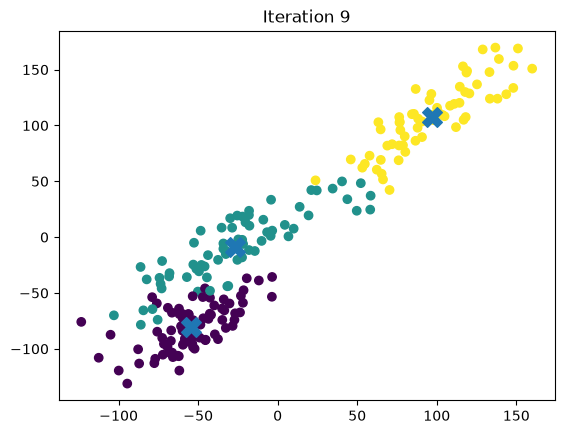

Stopped after 9 iterations.
Number of clusters found: 3
Silhouette score: 0.42212676242010666


In [37]:
max_iterations = 100
k = 3
centroids = get_centroids(train_data,k)
old_centroids = pd.DataFrame()
iteration = 1
while iteration < max_iterations and not centroids.equals(old_centroids):
    old_centroids = centroids.copy()
    labels = get_labels(train_data,centroids)
    centroids = new_centroids(train_data,labels,k)
    plot_clusters(train_data, labels, centroids,iteration)
    iteration +=1
print(f"Stopped after {iteration - 1} iterations.")
from sklearn.metrics import silhouette_score

labels = get_labels(train_data, centroids)

print("Number of clusters found:", len(np.unique(labels)))
print("Silhouette score:", silhouette_score(train_data, labels))